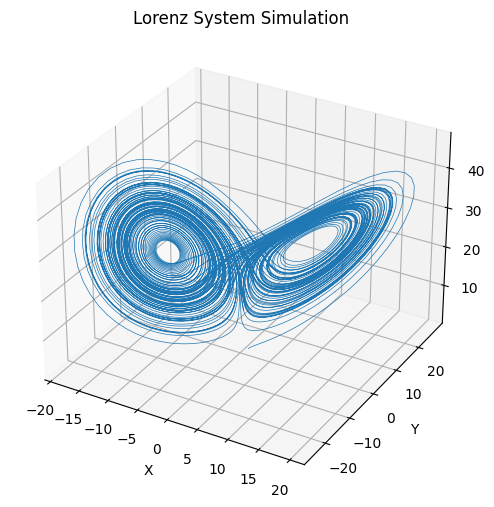

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
sigma = 10.0
rho = 28
beta = 8.0 / 3.0

# Lorenz system equations
def lorenz_system(state, t):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return np.array([dxdt, dydt, dzdt])

# Fourth-order Runge-Kutta method
def rk4_step(state, t, dt, system):
    k1 = system(state, t)
    k2 = system(state + 0.5 * dt * k1, t + 0.5 * dt)
    k3 = system(state + 0.5 * dt * k2, t + 0.5 * dt)
    k4 = system(state + dt * k3, t + dt)
    new_state = state + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return new_state

# Second-order Runge-Kutta method
def rk2_step(state, t, dt, system):
    k1 = system(state, t)
    k2 = system(state + dt * k1, t + dt)
    new_state = state + dt * k2
    return new_state

# Distance between two state vectors
def get_distance(state1, state2):
    return np.linalg.norm(np.array(state2) - np.array(state1))

# Simulation parameters
dt = 0.01
t_max = 100
num_steps = int(t_max / dt)

# Initial state
initial_state = np.array([1.0, 1.0, 1.0])

# Arrays to store results
time_points = np.linspace(0, t_max, num_steps)
state_trajectory = np.zeros((num_steps, 3))

# Simulation loop
state = initial_state
for i in range(num_steps):
    state_trajectory[i] = state
    state = rk4_step(state, time_points[i], dt, lorenz_system)

# Plotting the results
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(state_trajectory[:, 0], state_trajectory[:, 1], state_trajectory[:, 2], lw=0.5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Lorenz System Simulation')
plt.show()

You are given access to the following functions:

`system(state, t)`takes in $[x_0,x_1,x_2],t$ and outputs $[\dot{x}_0,\dot{x}_1,\dot{x}_2]$

`rk4_step(state, t, dt, system)` takes in $[x_0,x_1,x_2]$ at time $t$ and outputs the state at time $t+dt,$ when it is evolved through the inputed system.

`rk2_step(state, t, dt, system)` takes in $[x_0,x_1,x_2]$ at time $t$ and outputs the state at time $t+dt,$ when it is evolved through the inputed system.

`get_distance(state1, state2)` takes in two state vectors and returns the Cartesian distance between them.

In [ ]:
rk4_step([1,2,3],4,0.01,lorenz_system)

array([1.10668018, 2.24217232, 2.94309092])

# QUESTION 0: Prelims
What condition needs to be satisfied for $\sigma,\rho,\beta$ in order for the ODE to be stable? (i.e. bounded orbits). Where are the attractors located?

# QUESTION 1: Changing Parameters
Suppose you change the parameter $\rho$ slightly above its original value, and keep $\sigma$ and $\beta$ at their original values. How does the system behavior change? In particular, how does the position of the attractors change, and what happens to the system's stability?

Now suppose you keep $\rho$ at its original value, and change $\sigma$ and $\beta$ to values slightly different from their original ones. Again, describe the changes in the system behavior, the position of the attractors, and the system's stability.

# QUESTION 2: Wind
Suppose a constant wind of magnitude $100\;\mathrm{m/s}$ moves through the system. Describe what happens to the system and the thickness of lines. Does the position of the center move, and where? Modify the code we gave to output a new plot.

# QUESTION 3: Compute the Maximal Lyapunov Exponent (MLE)
For these parameters:

* $\sigma = 15.6$
* $\rho = 35.4$
* $\beta = 3.13$

See if you can estimate uncertainties!

# QUESTION 4: Comparing RK4 to RK2
Call $T_\text{max}$ the maximal time for when a simulation is accurate to $1\%$ of reality. A simulation is characterized by the specific numerical solver and the time step $dt.$

Using RK4, estimate $T_\text{max}$ at various values of $d{t},$ given the initial point of $(0,0,0).$ Make a plot.

Then do the same thing with RK2. What differences do you notice?

# QUESTION 5: Orbital Frequency

Let $\sigma = 10, \rho=28, \beta=8/3.$ What is the average angular frequency $\omega_0?$ Report with uncertainty. How does this change with position?